# 00 · Data audit and problem definition
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/00_data_audit_and_problem_definition.ipynb)

**Project:** reconstructing missing building-sensor measurements (MMA3001, Dataset 2: Monash Smart Infrastructure).

This notebook defines the engineering problem, audits the raw data, and fixes the choices every later notebook depends on (sensor, splits, occupancy proxy, gap lengths). It runs on CPU in about 2 minutes. On Colab: put the two Moodle zip files in `My Drive/MMA3001/raw/` first.

| Unit topic | Where it appears here |
|---|---|
| 1.2 Data management and version control | raw data kept out of git, reproducible preprocessing script, processed cache |
| 1.5 Testing, debugging and validation | auditing duplicates, error codes, implausible values, gaps |
| 3.2 Learning data noise | estimating the sensor's white-noise floor from first differences |
| 5.6 Training data evaluation and selection | chronological train/validation/test split; occupancy-proxy selection on training data only |
| 6.x Numerical integration | occupancy events converted to exact time-weighted means (integral of a step function) |

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import json
import numpy as np
import pandas as pd
from sensorfill import data, study, plotting
from sensorfill.plotting import plt
plotting.setup()
audit = json.loads((PROCESSED / "audit.json").read_text())
print(json.dumps({k: v for k, v in audit.items() if k not in (study.PRIMARY_SENSOR, study.SECONDARY_SENSOR)}, indent=1, default=str))

{
 "env_unique_readings": 42843,
 "env_readings_per_sensor": {
  "6012002000227": 1,
  "6012002000241": 2,
  "6012002000326": 29039,
  "6012002000777": 1,
  "6012002000869": 13800
 },
 "occ_events": 9091732,
 "occ_status_counts": {
  "CurrentlyOccupied": 8405894,
  "RecentlyOccupied": 420133,
  "NotOccupied": 265705
 },
 "occ_negative_or_huge_headcount": 0,
 "occ_spaces": [
  "0f3f37f8",
  "941f0352",
  "227f1068",
  "cca1ac3e",
  "3e5a14df"
 ]
}


## 1. The engineering problem

Building management systems (BMS) use indoor CO₂, temperature and humidity to control ventilation and HVAC, to verify indoor-air-quality compliance, and to estimate energy use. Wireless sensors drop readings: single packets are lost, batteries run flat and gateways go offline for hours or days. A gap breaks control loops and biases aggregated indicators such as the daily CO₂ dose or cooling degree-hours.

**Question.** Given a 10-minute indoor environmental series with gaps, and optionally building occupancy, how accurately can the missing values be reconstructed, and which numerical or machine-learning method should a BMS use for each gap length?

**Intended use.** Offline gap-filling of logged data before computing daily ventilation and comfort indicators. The methods may use data *after* a gap. A real-time controller would use only the forward-looking (IVP) variants.

**Scope and limits.** Gaps from 10 minutes to 24 hours. Longer outages (we found one of 15,000 h) are out of scope and are flagged rather than filled. The primary target is CO₂ in ppm, with temperature in °C as a secondary target.

### Inputs and outputs (top level)

| | Item | Format / units / domain | Handling of invalid input |
|---|---|---|---|
| **Input** | Env export (`5EnvSensor_*.zip`) | CSV with a JSON column; unix-second timestamps; CO₂ in ppm, T in °C, RH in %, p in mbar | duplicate uploads collapsed; `errorCode` records skipped; values outside `PLAUSIBLE_RANGE` set to NaN (not clipped) |
| **Input** | Occupancy export (`5occupancySensor_*.zip`) | change events: headcount (persons, ≥ 0) with local timestamps | headcount < 0 or > 200 dropped; silence > 72 h treated as an outage (NaN) |
| **Intermediate** | `env_<sensor>.parquet`, `occupancy.parquet` | regular 10-min local-time grid, NaN = missing | — |
| **Output** | Reconstructed series | same grid and units, observed values unchanged | edge gaps (no right-hand anchor) held at the last value and reported; gaps longer than a method's window fall back to linear |
| **Output** | Benchmark tables / figures | RMSE, MAE, bias, max error per gap length, runtime, memory | — |
| **Output** | Daily indicators | CO₂ excess dose (ppm·h), cooling degree-hours (K·h) | days with any NaN are returned as NaN |

## 2. Raw-data audit

In [3]:
rows = []
for sid in (study.PRIMARY_SENSOR, study.SECONDARY_SENSOR):
    a = audit[sid]
    rows.append({"sensor": sid, "start": a["start"], "end": a["end"], "grid points": a["n"],
                 "missing %": round(100 * a["frac_missing"], 1), "longest gap (steps)": a["longest_gap_steps"],
                 "implausible rejected": sum(a["rejected_implausible"].values())})
pd.DataFrame(rows)

,sensor,start,end,grid points,missing %,longest gap (steps),implausible rejected
0,6012002000869,2024-02-29 17:00:00,2024-06-14 03:50:00,15186,9.5,2,0
1,6012002000326,2025-09-07 20:10:00,2026-04-22 23:10:00,32707,11.2,646,0


In [4]:
pd.DataFrame({sid: audit[sid]["gap_histogram"] for sid in (study.PRIMARY_SENSOR, study.SECONDARY_SENSOR)}).rename_axis("gap length [steps of 10 min]")

,6012002000869,6012002000326
gap length [steps of 10 min],,
"[1.0, 2.0)",1422,2044
"[2.0, 4.0)",7,64
"[4.0, 7.0)",0,20
"[7.0, 19.0)",0,10
"[19.0, 37.0)",0,3
"[37.0, 145.0)",0,0
"[145.0, 1009.0)",0,2
"[1009.0, inf)",0,0


**Findings.**
* The env export has 179,447 rows but only 42,843 unique readings, because uploads are repeated. De-duplication is essential: without it, means and fitted models would weight some periods 4× more than others.
* Despite the file name ("May to Dec 2024"), the readings span Dec 2023 to Apr 2026. Only two sensors have usable series.
* Sensor `…869` (Building 60, G.38 Compactus upper, from the location sheet) has *only* 1–2-step dropouts. It is therefore the ideal sensor for validation: long artificial gaps can be hidden with clean ground truth around them.
* Sensor `…326` has realistic long gaps (up to 646 steps ≈ 4.5 days) plus a 15,000-hour outage (excluded by `longest_observed_window`).

**Distribution shift to keep in mind.** As the figure below shows, in the test period (from 22 May) occupancy, and therefore CO₂, is visibly lower than in training, which is consistent with the end of semester. A model that only memorised the training level would be biased. This is one reason the ML features are *relative* to the gap's own anchors (notebook 04).

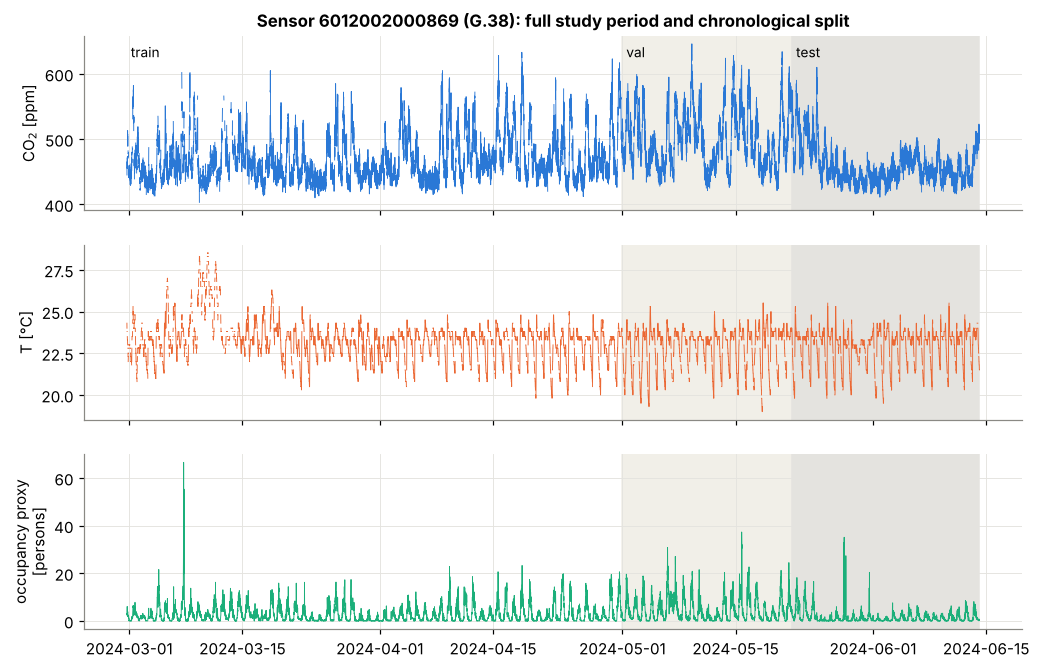

In [5]:
env = pd.read_parquet(PROCESSED / f"env_{study.PRIMARY_SENSOR}.parquet")
occ = pd.read_parquet(PROCESSED / "occupancy.parquet").reindex(env.index)
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(env.index, env["co2"], lw=0.6, color=plotting.PALETTE[0]); axes[0].set_ylabel("CO$_2$ [ppm]")
axes[1].plot(env.index, env["temp"], lw=0.6, color=plotting.PALETTE[1]); axes[1].set_ylabel("T [°C]")
axes[2].plot(occ.index, occ[study.OCC_PROXY_SPACES].sum(axis=1), lw=0.6, color=plotting.PALETTE[2]); axes[2].set_ylabel("occupancy proxy\n[persons]")
for name, (a, b) in {"train": (env.index[0], study.TRAIN_END), "val": (study.TRAIN_END, study.VAL_END), "test": (study.VAL_END, env.index[-1])}.items():
    for ax in axes:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color={"train": "#ffffff", "val": "#f1efe8", "test": "#e4e3df"}[name], zorder=-1)
    axes[0].text(pd.Timestamp(a), env["co2"].max(), " " + name, va="top", fontsize=9)
axes[0].set_title("Sensor 6012002000869 (G.38): full study period and chronological split")
_ = plotting.save(fig, "00_series_overview")

## 3. Occupancy: from events to a regular signal

The occupancy sensors report **changes**. More than 97 % of silences longer than an hour start right after a `NotOccupied` event, so silence means "still empty", not "missing". The correct 10-minute value is therefore the *time-weighted mean of a step function*. `data.time_weighted_step_mean` computes it exactly from the running integral $F(t)=\int N\,dt$, which is piecewise linear between events. A plain average of the events that fall in each bin would be biased towards busy periods, when events are dense.

In [6]:
tr = env.index < study.TRAIN_END
corr = pd.concat([env["co2"], occ, occ[study.OCC_PROXY_SPACES].sum(axis=1).rename("proxy (sum of 4)")], axis=1)
summary = pd.DataFrame({
    "corr with CO2 (train)": corr[tr].corr()["co2"].drop("co2"),
    "missing in train %": 100 * corr[tr].isna().mean().drop("co2"),
}).round(3)
summary

,corr with CO2 (train),missing in train %
0f3f37f8,0.471,0.00
941f0352,0.601,0.00
227f1068,0.412,4.77
cca1ac3e,0.389,4.77
3e5a14df,NaN,100.00
proxy (sum of 4),0.582,0.00


**Choosing the occupancy proxy using training data only.** Space `3e5a14df` has the highest correlation overall, but it reports nothing before May. It would be absent for the entire training period, so selecting it would leak information from the test period. The **sum of the four spaces that report throughout** (r ≈ 0.58 on training data) is used instead.

None of the five floor spaces is confirmed to be the CO₂ sensor's room: the location sheet's occupancy tab is marked "Incorrect Data". The proxy therefore measures *building activity*, and any physical parameter estimated from it is an *effective* one. This is a stated limitation.

## 4. Noise floor

If the sensor noise is white with standard deviation σ, then first differences have variance 2σ², so σ ≈ std(Δy)/√2. No method can predict noise, so this σ is a lower bound on the point RMSE of *any* reconstruction scored against raw readings.

In [7]:
noise = {}
for c in ["co2", "temp", "rh", "pressure"]:
    y = env.loc[tr, c]
    noise[c] = {"unit": data.UNITS[c], "signal std": y.std(), "noise sigma ~ std(diff)/sqrt2": y.diff().std() / np.sqrt(2),
                "lag-1 autocorr": y.autocorr(1), "lag-1 day autocorr": y.autocorr(144)}
noise_df = pd.DataFrame(noise).T
noise_df

,unit,signal std,noise sigma ~ std(diff)/sqrt2,lag-1 autocorr,lag-1 day autocorr
co2,ppm,37.035491,8.552786,0.946155,0.441266
temp,degC,1.156578,0.100593,0.991743,0.765872
rh,%RH,7.513624,0.387192,0.997244,0.371982
pressure,mbar,5.160974,0.208517,0.998401,0.527679


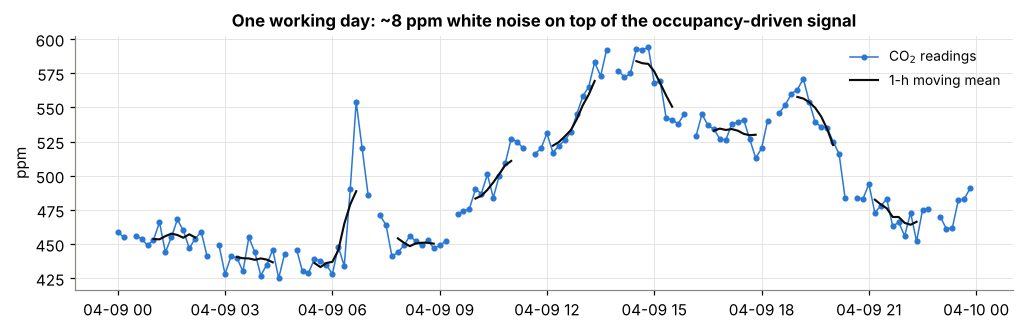

In [8]:
fig, ax = plt.subplots(figsize=(11, 3))
day = env.loc["2024-04-09"]
ax.plot(day.index, day["co2"], marker="o", ms=3, lw=1, color=plotting.PALETTE[0], label="CO$_2$ readings")
ax.plot(day.index, day["co2"].rolling(6, center=True).mean(), color=plotting.INK, lw=1.4, label="1-h moving mean")
ax.set_ylabel("ppm"); ax.set_title("One working day: ~8 ppm white noise on top of the occupancy-driven signal"); ax.legend()
_ = plotting.save(fig, "00_noise_day")

**Implication.** CO₂ noise is σ ≈ 8 ppm (an upper estimate, because the true signal also changes between samples), almost a quarter of the signal's standard deviation. For gaps of one or two samples, the error of interpolating between two *single noisy* readings is dominated by that noise. This motivates averaging several readings at each gap end (notebook 01). Temperature is much smoother relative to its variation, so its short-gap errors are expected to be very small.

## 5. Decisions carried forward (`sensorfill.study`)

In [9]:
s = study.load_study(PROCESSED, "co2")
print({k: int((s.split == k).sum()) for k in ("train", "val", "test")}, "points per split")
print("artificial gap lengths [steps]:", study.GAP_LENGTHS, "= 10 min ... 24 h")
print("training median CO2 (feature reference level):", s.level_ref, "ppm")

{'train': 8826, 'val': 3024, 'test': 3336} points per split
artificial gap lengths [steps]: (1, 3, 6, 18, 36, 72, 144) = 10 min ... 24 h
training median CO2 (feature reference level): 460.0 ppm
